# CNN + LSTM + CTC: check your local handwriting images

Load the selected **IAM epoch 14** checkpoint and read the images under `data/local/`, using the existing `templates/local_images.csv` manifest. No training, spelling correction, or optional preprocessing runs here. Required image preparation remains the saved model's grayscale/height-64 policy.

Correct text comes from your manifest unchanged. These local examples are a separate diagnostic, not IAM validation/test results and not a new checkpoint-selection study. Re-running this notebook creates a fresh result directory.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
from datetime import datetime, timezone
from importlib.metadata import version
import textwrap

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/load_dataset/local.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import display
from src.load_dataset.local import load_local_samples
from src.models import CNNLSTMCTCRecognizer
from src.preprocessing import PreprocessingPipeline
from src.evaluation.recognition import compare_recognition, corpus_metrics

MANIFEST = ROOT / "templates/local_images.csv"
CHECKPOINT = ROOT / "results/cnn_lstm_ctc/training/20261114_baseline/iam/best.pt"
SPLIT = "validation"
DEVICE = "cpu"
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)


## Load every listed local image

The existing loader corrects EXIF orientation, composites transparency onto white, and returns RGB copies without overwriting source files. This applies consistently before the recognizer's required preparation. Blank ground truth permits prediction without scoring; filled labels are scored as provided.


In [2]:
manifest_bytes = MANIFEST.read_bytes()
samples = load_local_samples(MANIFEST, split=SPLIT)
extensions = set(PILImage.registered_extensions())
available = {p.resolve() for p in (ROOT / "data/local").rglob("*")
             if p.is_file() and p.suffix.lower() in extensions}
listed = {(MANIFEST.parent / s["image_path"]).resolve() for s in samples}
if available != listed:
    raise ValueError("The selected manifest must cover all data/local images for this check; review listed paths/splits.")
print("Local images:", len(samples), "| labeled:", sum(s["ground_truth"] is not None for s in samples))
display(pd.DataFrame([{"image": s["id"], "size": s["original_size"], "correct_text": s["ground_truth"]}
                      for s in samples]))


Local images: 10 | labeled: 10


,image,size,correct_text
0,img01,"(1453, 178)",The sky is a deep blue color today
1,img02,"(1367, 177)",Please bring my notebook tomorrow
2,img03,"(1425, 179)",She wrote a letter to her friend
3,img04,"(1351, 174)",The train leaves at past helf time
4,img05,"(1130, 178)",I bought three apples and two pears
5,img06,"(1813, 145)",I was about to leave the house when I realized
6,img07,"(1969, 190)","As far as I know, they haven't made a final de..."
7,img08,"(1880, 180)","I've been meaning to get around to it, but som..."
8,img09,"(740, 162)",It slipped my mind
9,img10,"(948, 169)",I'm running a bit late


## Read the images using the trained model

The empty optional pipeline is the baseline. Each image is decoded greedily using the checkpoint's character IDs. Model loading time is excluded from recorded inference time. All original image files and checkpoint bytes are checked afterward for preservation.


In [3]:
recognizer = CNNLSTMCTCRecognizer.from_checkpoint(CHECKPOINT, device=DEVICE)
recognizer.model.eval()
model_config = recognizer.to_config()
assert model_config["checkpoint_epoch"] == 14
checkpoint_sha256 = model_config["checkpoint_sha256"]
rows, summaries = compare_recognition(samples, recognizer, {"baseline": PreprocessingPipeline()})
assert len(rows) == len(samples)
assert [r["sample_id"] for r in rows] == [s["id"] for s in samples]
for sample in samples:
    source = (MANIFEST.parent / sample["image_path"]).resolve()
    assert hashlib.sha256(source.read_bytes()).hexdigest() == sample["sha256"]
assert hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest() == checkpoint_sha256
assert MANIFEST.read_bytes() == manifest_bytes
predictions = pd.DataFrame(rows)
summary = pd.DataFrame(summaries)
display(predictions[["sample_id", "ground_truth", "prediction", "cer", "wer"]])
display(summary)
print("CER/WER are fractions; lower is better. Local manifest labels are used unchanged.")


baseline: 1/10
baseline: 2/10
baseline: 3/10
baseline: 4/10
baseline: 5/10
baseline: 6/10
baseline: 7/10
baseline: 8/10
baseline: 9/10
baseline: 10/10
CER/WER are fractions; lower is better. Local manifest labels are used unchanged.


,sample_id,ground_truth,prediction,cer,wer
0,img01,The sky is a deep blue color today,The sky is a der loe caoo todby .,0.294118,0.625000
1,img02,Please bring my notebook tomorrow,PPease bring mny nstebook fomorrow .,0.181818,1.000000
2,img03,She wrote a letter to her friend,T he wrote a letter to her frond,0.125000,0.428571
3,img04,The train leaves at past helf time,Th train leaver af posf hoff time .,0.264706,0.857143
4,img05,I bought three apples and two pears,T bogf thae anks and the pars .,0.428571,1.000000
5,img06,I was about to leave the house when I realized,Twas about to teave thehouse when I reatired .,0.173913,0.700000
6,img07,"As far as I know, they haven't made a final de...","Rifax as( know""ther hevenitiade afiatesiengs .",0.438596,1.000000
7,img08,"I've been meaning to get around to it, but som...","T he been meaning to get aroung toit , but som...",0.153846,0.600000
8,img09,It slipped my mind,It slippdmy mingd .,0.277778,0.750000
9,img10,I'm running a bit late,Ton waning abot fafe .,0.545455,1.000000


,configuration,sample_count,scored_sample_count,cer,wer,inference_seconds
0,baseline,10,10,0.280992,0.786667,0.304611


## View each image with the actual prediction

The preview displays the original local handwriting, the provided correct text, and the model's prediction. It does not represent optional image cleanup or corrected model output.


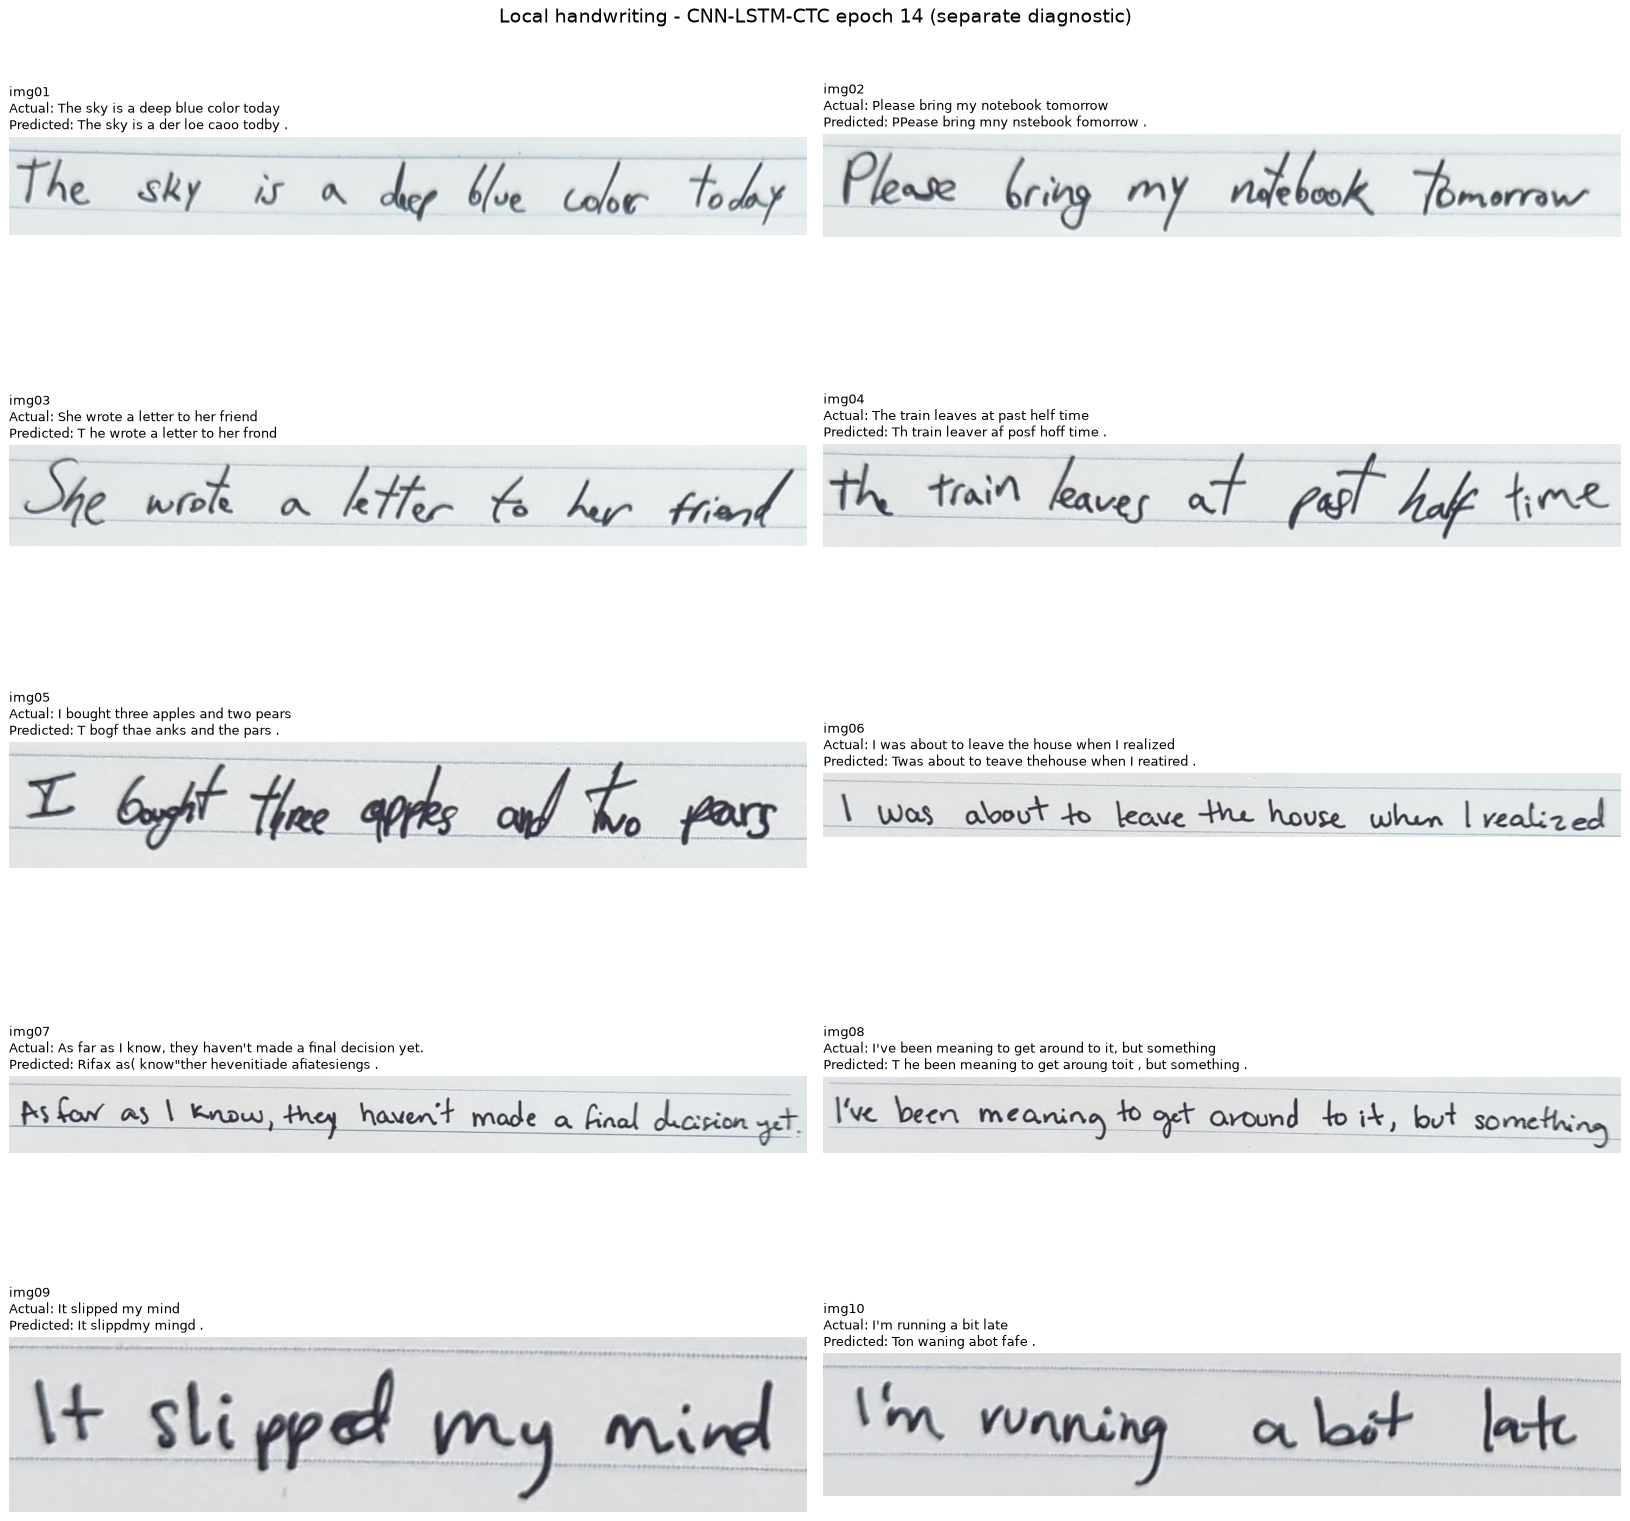

In [4]:
columns = 2
row_count = (len(samples) + columns - 1) // columns
fig, axes = plt.subplots(row_count, columns, figsize=(18, max(4, row_count * 3.5)), squeeze=False,
                         layout="constrained")
lookup = predictions.set_index("sample_id")
for ax, sample in zip(axes.flat, samples):
    prediction = lookup.loc[sample["id"], "prediction"]
    ax.imshow(sample["image"])
    correct = sample["ground_truth"] or "(unlabeled)"
    title = sample["id"] + "\nActual: " + textwrap.fill(correct, 72)
    title += "\nPredicted: " + textwrap.fill(prediction or "(empty)", 72)
    ax.set_title(title, fontsize=10, loc="left")
    ax.axis("off")
for ax in list(axes.flat)[len(samples):]:
    ax.axis("off")
fig.suptitle("Local handwriting - CNN-LSTM-CTC epoch 14 (separate diagnostic)", fontsize=15)
plt.show()


## Save reproducible local results

Exports include predictions, corpus scores, image hashes, manifest snapshot, checkpoint SHA-256/epoch, input configuration, software versions, a readable table, and the image preview. Original files and the final IAM training records remain unchanged.


In [5]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output = ROOT / "results/cnn_lstm_ctc/local_predictions" / run_id
output.mkdir(parents=True, exist_ok=False)
predictions.to_csv(output / "predictions.csv", index=False)
summary.to_csv(output / "summary.csv", index=False)
fig.savefig(output / "images_and_predictions.png", dpi=120, bbox_inches="tight")
plt.close(fig)
metadata = {
    "experiment_id": run_id, "phase": "local_images_diagnostic", "dataset": "local_images",
    "split": SPLIT, "manifest": str(MANIFEST.relative_to(ROOT)),
    "manifest_sha256": hashlib.sha256(manifest_bytes).hexdigest(),
    "manifest_contents": manifest_bytes.decode("utf-8-sig"),
    "samples": [{k: v for k, v in s.items() if k != "image"} for s in samples],
    "model": model_config, "cpu_threads": torch.get_num_threads(),
    "optional_preprocessing": PreprocessingPipeline().to_config(),
    "local_input_adaptation": "EXIF transpose; white alpha composite; RGB; original files preserved",
    "normalization": "collapse whitespace; retain case and punctuation",
    "scoring": "corpus edit counts / reference counts; only labeled samples",
    "python": platform.python_version(),
    "versions": {p: version(p) for p in ("torch", "numpy", "Pillow", "jiwer", "pandas", "matplotlib")},
    "training_started": False, "iam_test_evaluated": False,
    "source_images_manifest_and_checkpoint_unchanged": True,
}
(output / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
def escape(text):
    return str(text).replace("|", r"\|").replace("\n", "<br>")
lines = ["# Local handwriting: CNN-LSTM-CTC epoch 14", "",
         f"Read {len(samples)} local images with the selected IAM checkpoint. No training or optional preprocessing ran.",
         "Correct text is copied from the local manifest unchanged. This is a local diagnostic, not final IAM test performance.", ""]
scored = summaries[0]
if scored["scored_sample_count"]:
    lines += [f"Corpus CER: **{100*scored['cer']:.2f}%**; WER: **{100*scored['wer']:.2f}%** on {scored['scored_sample_count']} labeled local images.", ""]
lines += ["| Image | Correct text | Model prediction |", "| --- | --- | --- |"]
for row in rows:
    lines.append(f"| {escape(row['sample_id'])} | {escape(row['ground_truth'] or '(unlabeled)')} | {escape(row['prediction'] or '(empty)')} |")
lines += ["", "[Full predictions CSV](predictions.csv) | [Corpus summary](summary.csv) | [Run metadata](metadata.json)",
          "", "![Local images with actual and predicted text](images_and_predictions.png)"]
(output / "PREDICTIONS.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("Saved local predictions:", output)


Saved local predictions: C:\Users\chirayu ubale\OneDrive\Desktop\Research Project\results\cnn_lstm_ctc\local_predictions\20261115T054718447180Z
